# Long Short-Term Memory Network (LSTM) for Detecting AI Written Text


This LSTM model is designed to detect AI written text.

## Imports and Variable Declaration

In [2]:
!pip install torchtext

In [8]:
import numpy as np
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torch.utils.data.sampler import SubsetRandomSampler
import torchvision.transforms as transforms

import tensorflow as tf

import torchtext
from torchtext.vocab import GloVe

import matplotlib.pyplot as plt

import random

I0000 00:00:1793897182.528041     344 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [17]:
# Variables
input_size = 50 # embedding size
hidden_size = 100 # hidden layer size
num_layers = 1  # number of layers
num_classes = 2 # number of classes/outputs
batch_size = 100 # batch size max
num_epochs = 1 # number of epochs
learning_rate = 0.01 # learning rate
bidirectional = False # bidirectional or not
bidirect = (int(bidirectional)+1) # converting bidirectional boolean to 1 or 2 so number of layers can be multiplied by this coefficient

In [18]:
# Create the cache directory torchtext looks for
!mkdir -p .vector_cache

# Download the GloVe zip from a reliable HuggingFace mirror
!wget https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip -O .vector_cache/glove.6B.zip

# Unzip it so the text files are ready
!unzip -q .vector_cache/glove.6B.zip -d .vector_cache/

--2026-11-05 16:50:53--  https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip
Resolving huggingface.co (huggingface.co)... 13.226.251.112, 13.226.251.81, 13.226.251.20, ...
Connecting to huggingface.co (huggingface.co)|13.226.251.112|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/621ffdc136468d709f18095d/ded22944ac944002f423d1cdb83de044851330e1a7fe19d74dc59ffa632ad294?xip=TUa__hb0LXA&X-Xet-Cas-Uid=public&user_id=public&response-content-type=application%2Fzip&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27glove.6B.zip%3B+filename%3D%22glove.6B.zip%22%3B&Expires=1793901053&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjIxZmZkYzEzNjQ2OGQ3MDlmMTgwOTVkL2RlZDIyOTQ0YWM5NDQwMDJmNDIzZDFjZGI4M2RlMDQ0ODUxMzMwZTFhN2ZlMTlkNzRkYzU5ZmZhNjMyYWQyOTRcXD94aXA9VFVhX19oYjBMWEEmWC1YZXQtQ2FzLVVpZD1wdWJsaWMmdXNlcl9pZD1wdWJsaWMmcmVzcG9uc2UtY29udGVudC10eXBlPSomcmV

In [23]:
# Downloading glove
glove = torchtext.vocab.GloVe(name ="6B", dim=input_size) # embedding size

## Data Processing

Retrieving the data from the respective files, spliting the text, and embbeding. The data has already been cleaned and throughly processed in another code.

In [24]:
# Function to retrieve data from csv file
import csv
def get_data(data_type):
    return csv.reader(open("/kaggle/input/notebooks/gitbyjay25/data-preprocessing/" + data_type + ".csv", "rt", encoding="latin-1"))

In [25]:
# Retrieving data from the respective csv files
train = get_data("train")
val = get_data("val")
test = get_data("test")

In [26]:
# Embbeds the text using GloVe
def get_words(glove_vector, data_type):
    output = []
    for i, line in enumerate(get_data(data_type)):
        if i == 0: # skip first line with titles of columns
            continue
        text = line[0] # column with text
        idxs = [glove_vector.stoi[w] for w in text.split() if w in glove_vector.stoi]
        if not idxs: # ignore texts without any word with an embedding
            continue
        idxs = torch.tensor(idxs)
        label = torch.tensor(int(line[1] == "1")).long()
        output.append((idxs, label))

    return output

In [27]:
# Embbeds each dataset
train_list = get_words(glove, "train")
val_list = get_words(glove, "val")
test_list = get_words(glove, "test")

## Model

The model class, contains the specifications of what layers will be used.

In [28]:
# RNN model
class RNN(nn.Module):
  def __init__(self,input_size,hidden_size,num_class,num_layers,bidirectional):
    super(RNN,self).__init__()
    # look up the embeddings
    self.emb = nn.Embedding.from_pretrained(glove.vectors)
    self.hidden_size = hidden_size
    self.num_layers = num_layers
    self.bidirectional = bidirectional
    self.bidirect = 2 if bidirectional else 1
    # set up RNN
    self.rnn = nn.LSTM(input_size,hidden_size,num_layers=num_layers,bidirectional=bidirectional,batch_first=True)
    self.norm = nn.LayerNorm(hidden_size * self.bidirect)
    self.fc = nn.Linear(hidden_size * self.bidirect, num_classes)

  def forward(self,x):
    # look up the embeddings
    x=self.emb(x)
    # set the intial hidden states
    h0 = torch.zeros(bidirect*self.num_layers,x.size(0),self.hidden_size)
    c0 = torch.zeros(bidirect*self.num_layers,x.size(0),self.hidden_size)

    # forward propagate the RNN
    out,__ = self.rnn(x,(c0,h0))
    out = self.norm(out)
    # pass maxpool over all outputs to the classifier
    return self.fc(torch.max(out, dim=1)[0])



In [25]:
# Set up default RNN with default values
default_model = RNN(input_size,hidden_size,num_classes,num_layers, bidirectional)

## Batching

The texts in the data set vary in lengths, which poses an issue for the model. To address this, texts with the same lengths are grouped together and form the batches for the model to use.

In [35]:
# batch texts of similar lengths together
class TextBatcher:
    def __init__(self, text, batch_size=32, drop_last=False):
        # store texts by length
        self.text_by_length = {}
        for words, label in text:
            # compute the length of the text
            wlen = words.shape[0]
            # put the text in the correct key inside self.text_by_length
            if wlen not in self.text_by_length:
                self.text_by_length[wlen] = []
            self.text_by_length[wlen].append((words, label),)

        #  create a DataLoader for each set of text of the same length
        self.loaders = {wlen : torch.utils.data.DataLoader(
                                    text,
                                    batch_size=batch_size,
                                    shuffle=True,
                                    drop_last=drop_last) # omit last batch if smaller than batch_size
            for wlen, text in self.text_by_length.items()}

    def __iter__(self): # called by Python to create an iterator
        # make an iterator for every text length
        iters = [iter(loader) for loader in self.loaders.values()]
        while iters:
            # pick an iterator (a length)
            im = random.choice(iters)
            try:
                yield next(im)
            except StopIteration:
                # no more elements in the iterator, remove it
                iters.remove(im)



## Model Training

Calculating the accuracy of the model, training the model, and plotting the results.

In [39]:
# calculate accuracy of model
def get_accuracy(model, data_loader):
    correct, total = 0, 0
    # iterating through loaded data
    for text, labels in data_loader:
        output = model(text)
        # calculating predication
        pred = output.max(1, keepdim=True)[1]
        # adding up number of correct predictions
        correct += pred.eq(labels.view_as(pred)).sum().item()
        # adding up total number of texts
        total += labels.shape[0]
    if(total>0):
      return correct/total
    else:
      return 0

In [40]:
def train_rnn_network(name, model, train_loader, val_loader, num_epochs=num_epochs, learning_rate=learning_rate):
    start_time = time.time()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    losses, train_acc, valid_acc = [], [], []
    epochs = []

    if not isinstance(model, nn.Module):
        raise ValueError("Provided model is not a PyTorch neural network module")

    # iterate through epochs
    for epoch in range(num_epochs):
        # set model to training mode
        model.train()
        epoch_losses = []
        # iterate through training data
        for text, labels in train_loader:
            optimizer.zero_grad()
            pred = model(text)
            loss = criterion(pred, labels)
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())

        # compute loss
        avg_epoch_loss = sum(epoch_losses) / len(epoch_losses)
        losses.append(avg_epoch_loss)

        # compute accuracy
        epochs.append(epoch)
        train_acc.append(get_accuracy(model, train_loader))
        valid_acc.append(get_accuracy(model, val_loader))
        print("Epoch %d; Loss %f; Train Acc %f; Val Acc %f" % (
              epoch+1, avg_epoch_loss, train_acc[-1], valid_acc[-1]))

        model_path = "model_{0}_epoch{1}.pth".format(name, epoch+1)
        torch.save(model.state_dict(), model_path)

    end_time = time.time()
    elapsed_time = end_time - start_time
    print("Total time elapsed: {:.2f} seconds".format(elapsed_time))

    # plot training curve
    plt.title("Training Curve")
    plt.plot(epochs, losses, label="Train Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

    # plot accuracy curve
    plt.title("Accuracy Curve")
    plt.plot(epochs, train_acc, label="Train Accuracy")
    plt.plot(epochs, valid_acc, label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend(loc='best')
    plt.show()
    return model

##Declare Batches

Set up the batches for the training and validation datasets

In [36]:
train_loader = TextBatcher(train_list, batch_size=batch_size, drop_last=False)

In [37]:
val_loader = TextBatcher(val_list, batch_size=batch_size, drop_last=False)

## Default Model 

Training the model on default values. This includes using an LSTM with 1 layer, layer normalization, and max pooling. See the variables declaration section to see more details about the default results.

Epoch 1; Loss 0.343566; Train Acc 0.861636; Val Acc 0.746390
Total time elapsed: 113.45 seconds


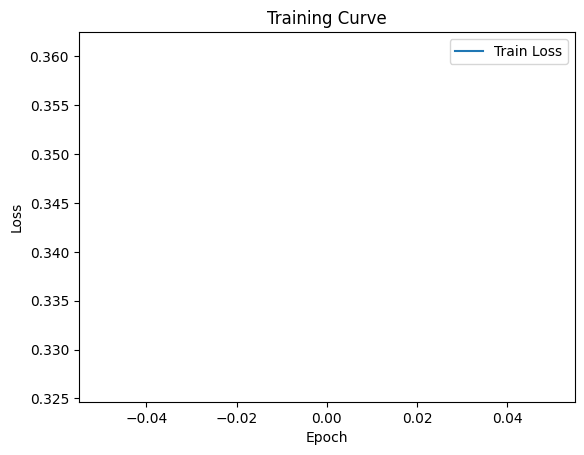

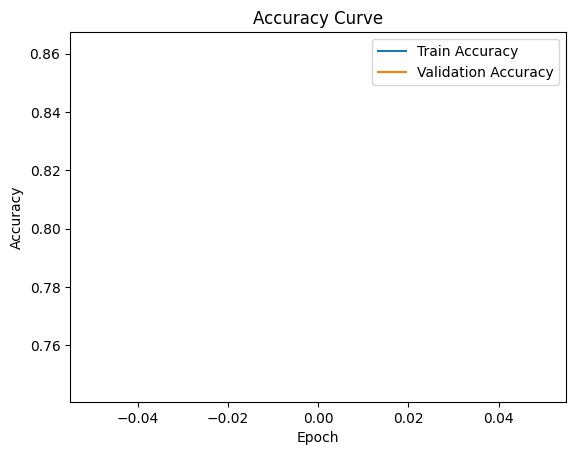

RNN(
  (emb): Embedding(400001, 50)
  (rnn): LSTM(50, 100, batch_first=True)
  (norm): LayerNorm((100,), eps=1e-05, elementwise_affine=True)
  (fc): Linear(in_features=100, out_features=2, bias=True)
)

In [31]:
train_rnn_network("LSTM",default_model, train_loader, val_loader, num_epochs=1, learning_rate=learning_rate)

## Tuning Hyperparameters
Tuning learning rate, hidden units, number of layers, and dropout rate.

### Tuning by Sweeping

Validating model performace on learning rates from 0.001 to 0.05, hidden units from 50 to 200, number of layers 1 to 3, and droupout rates 0.2 to 0.5.

Testing Learning Rate: 0.001
Epoch 1; Loss 0.177147; Train Acc 0.970190; Val Acc 0.843447
Total time elapsed: 109.30 seconds


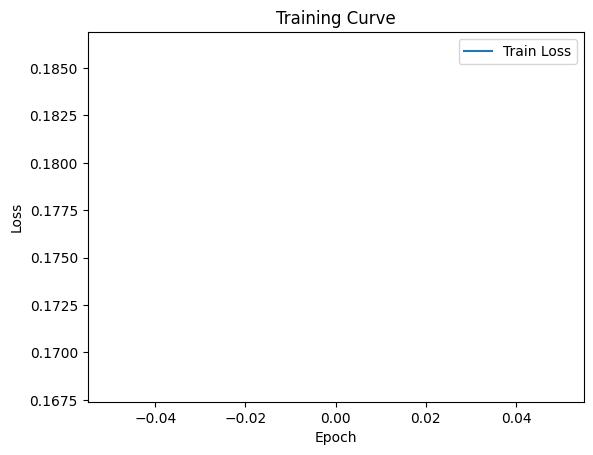

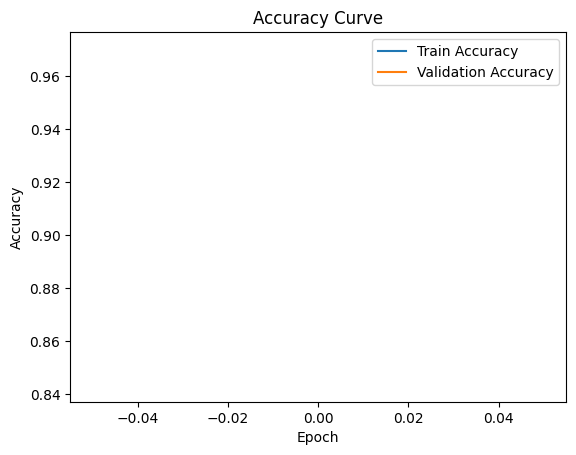



Testing Learning Rate: 0.005
Epoch 1; Loss 0.232585; Train Acc 0.962851; Val Acc 0.797935
Total time elapsed: 111.91 seconds


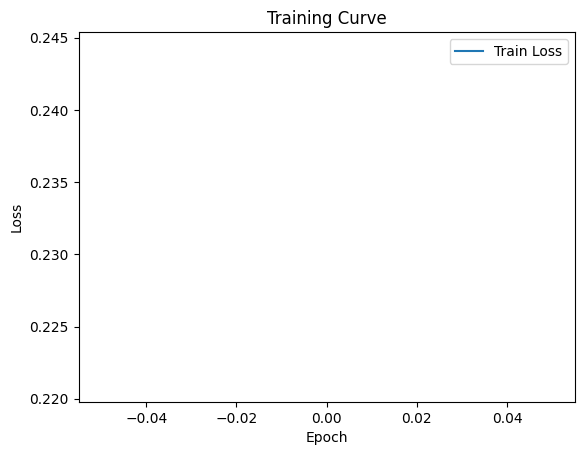

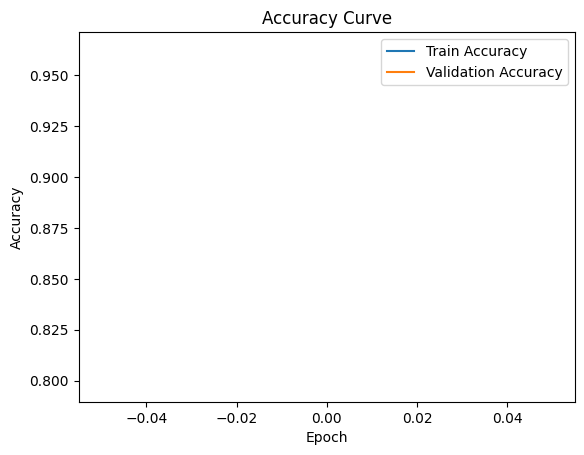



Testing Learning Rate: 0.01
Epoch 1; Loss 0.492595; Train Acc 0.835571; Val Acc 0.672546
Total time elapsed: 114.45 seconds


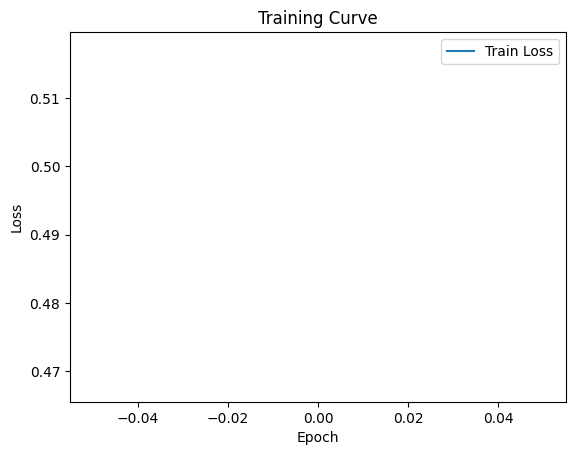

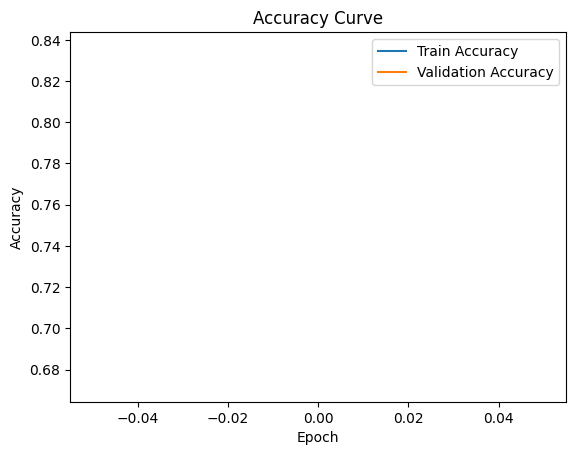



Testing Learning Rate: 0.02
Epoch 1; Loss 0.385049; Train Acc 0.831582; Val Acc 0.721349
Total time elapsed: 153.95 seconds


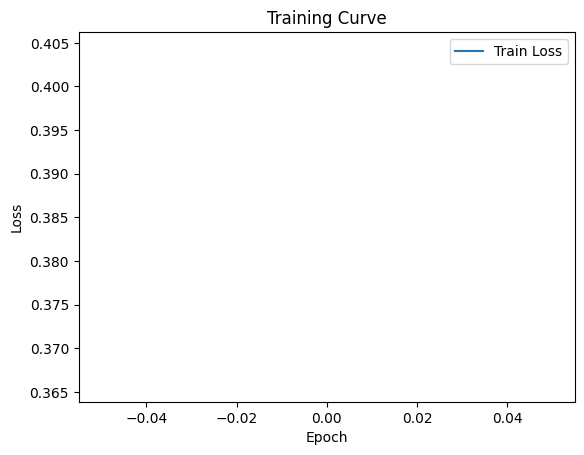

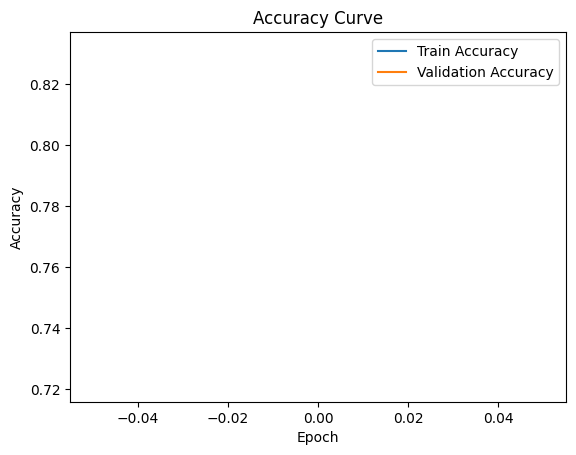



Testing Learning Rate: 0.05
Epoch 1; Loss 0.663013; Train Acc 0.598307; Val Acc 0.438128
Total time elapsed: 607.28 seconds


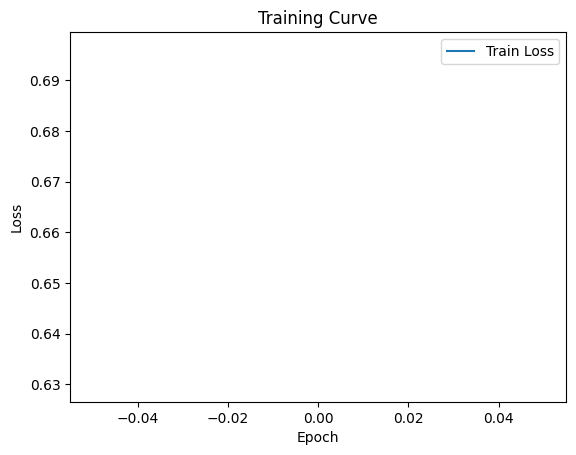

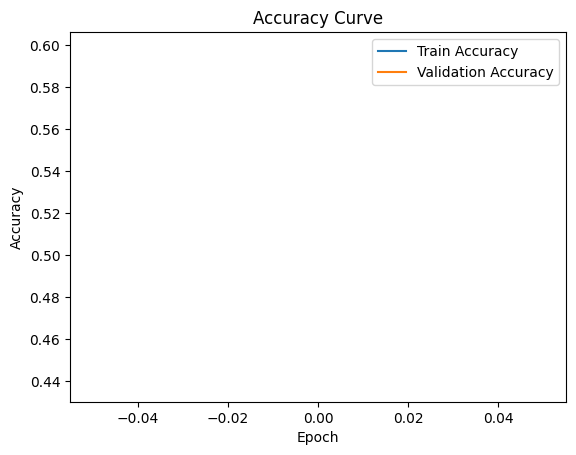

In [32]:
def test_learning_rate(train_loader, val_loader, learning_rates, input_size, hidden_size, num_classes, num_layers, num_epochs):
    for lr in learning_rates:
        print(f"Testing Learning Rate: {lr}")
        model = RNN(input_size, hidden_size, num_classes, num_layers, bidirectional)
        train_rnn_network(str("LSTM_lr_" + str(lr)), model, train_loader, val_loader, num_epochs=1, learning_rate=lr)
        print("\n")

learning_rates = [0.001, 0.005, 0.01, 0.02, 0.05]
test_learning_rate(train_loader, val_loader, learning_rates, input_size, hidden_size, num_classes, num_layers, num_epochs)

Testing Hidden Layer Size: 50
Epoch 1; Loss 0.219235; Train Acc 0.912944; Val Acc 0.763297
Total time elapsed: 61.99 seconds


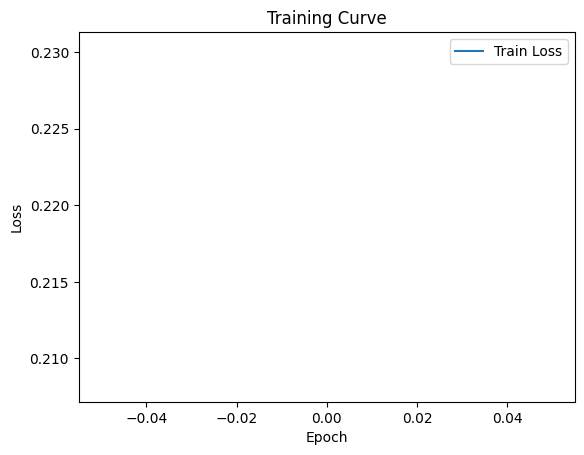

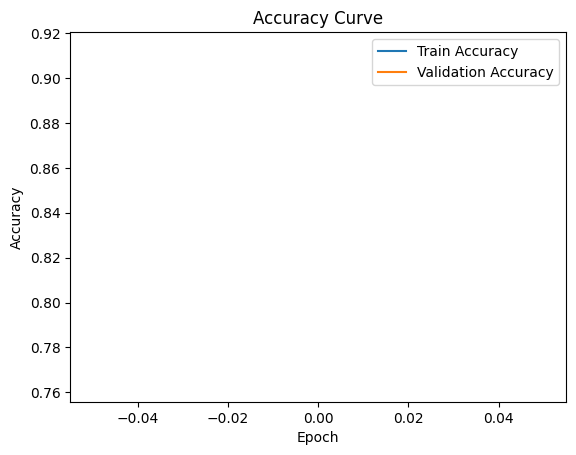

Testing Hidden Layer Size: 100
Epoch 1; Loss 0.289463; Train Acc 0.957279; Val Acc 0.841985
Total time elapsed: 121.52 seconds


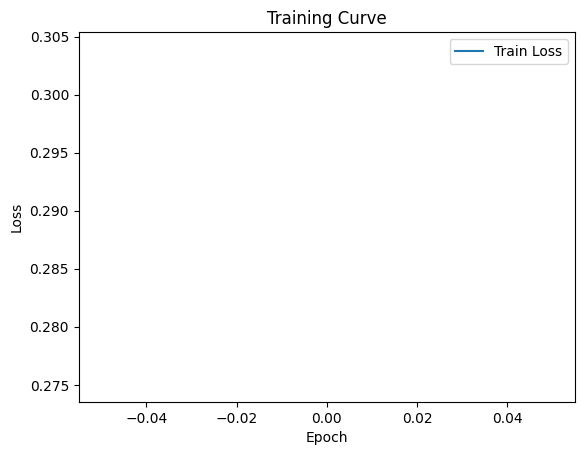

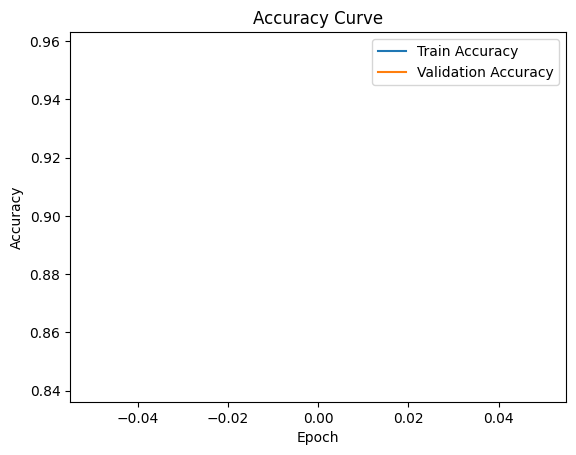

Testing Hidden Layer Size: 200
Epoch 1; Loss 0.393075; Train Acc 0.878018; Val Acc 0.744836
Total time elapsed: 273.89 seconds


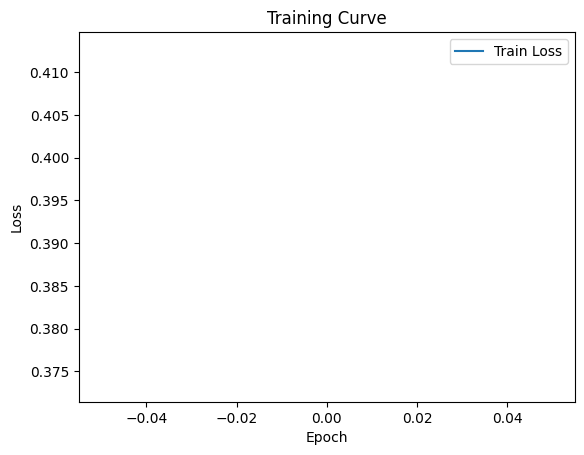

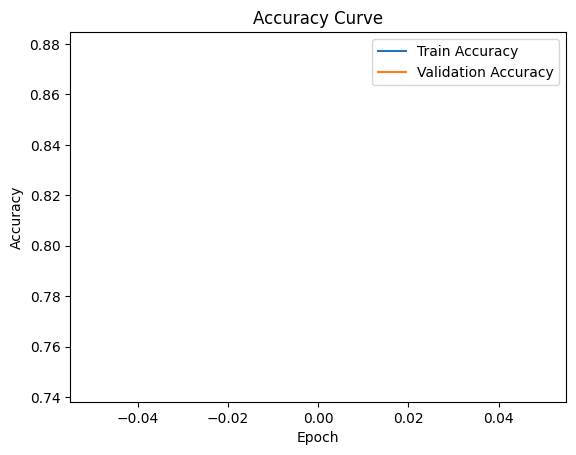

In [33]:
def test_hidden_sizes(train_loader, val_loader, hidden_sizes):
    for hidden_size in hidden_sizes:
        print(f"Testing Hidden Layer Size: {hidden_size}")
        model = RNN(input_size, hidden_size, num_classes, num_layers, bidirectional)
        train_rnn_network("LSTM_hs_" + str(hidden_size), model, train_loader, val_loader, num_epochs, learning_rate)

hidden_sizes = [50, 100, 200]
test_hidden_sizes(train_loader, val_loader, hidden_sizes)

Testing Number of Layers: 1
Epoch 1; Loss 0.446560; Train Acc 0.886392; Val Acc 0.781576
Total time elapsed: 122.40 seconds


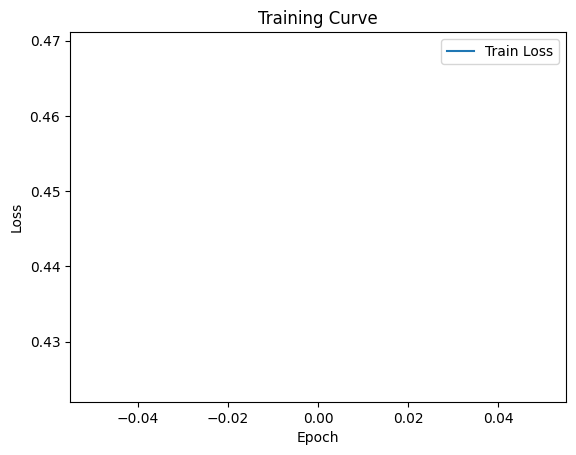

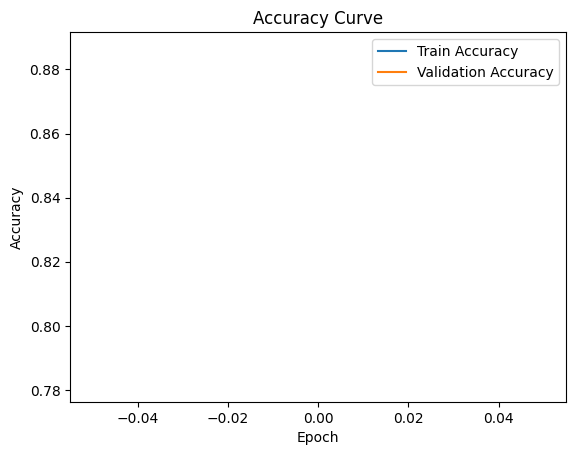

Testing Number of Layers: 2
Epoch 1; Loss 0.582161; Train Acc 0.670199; Val Acc 0.601261
Total time elapsed: 287.70 seconds


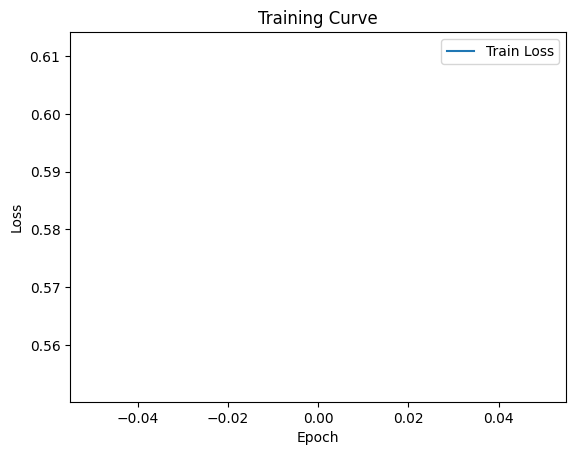

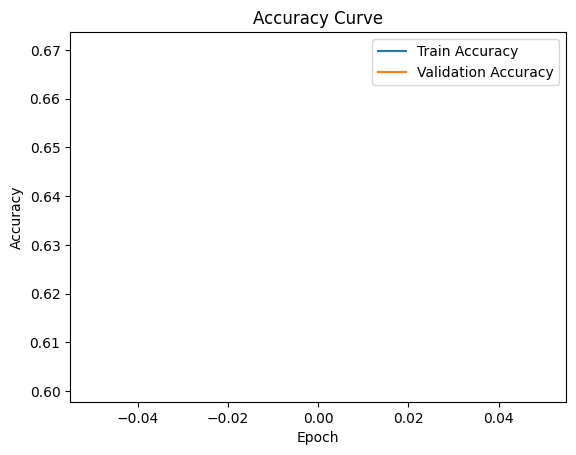

Testing Number of Layers: 3
Epoch 1; Loss 0.598695; Train Acc 0.652538; Val Acc 0.597788
Total time elapsed: 388.63 seconds


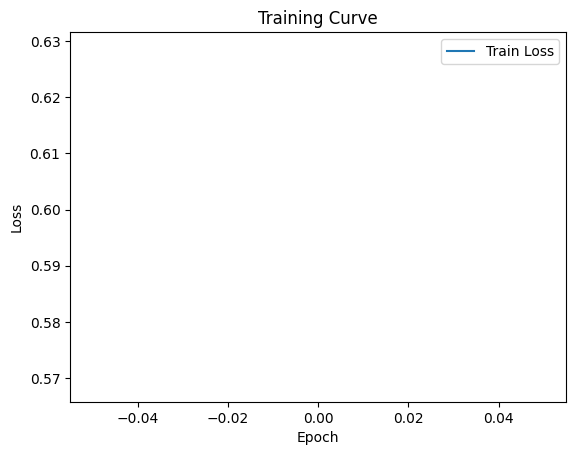

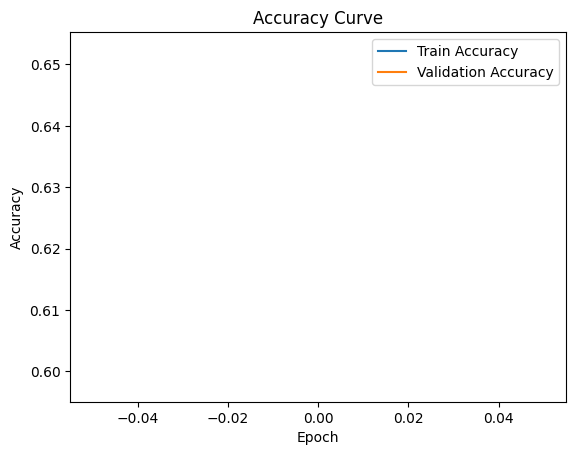

In [34]:
def test_num_layers(train_loader, val_loader, num_layers_list):
    for num_layers in num_layers_list:
        print(f"Testing Number of Layers: {num_layers}")
        model = RNN(input_size, hidden_size, num_classes, num_layers=num_layers, bidirectional=False)
        train_rnn_network("LSTM_nl_" + str(num_layers), model, train_loader, val_loader, num_epochs=1, learning_rate=learning_rate)

num_layers_list = [1, 2, 3]
test_num_layers(train_loader, val_loader, num_layers_list)

Testing Dropout Rate: 0.2
Epoch 1; Loss 0.294840; Train Acc 0.933741; Val Acc 0.777463
Total time elapsed: 120.85 seconds


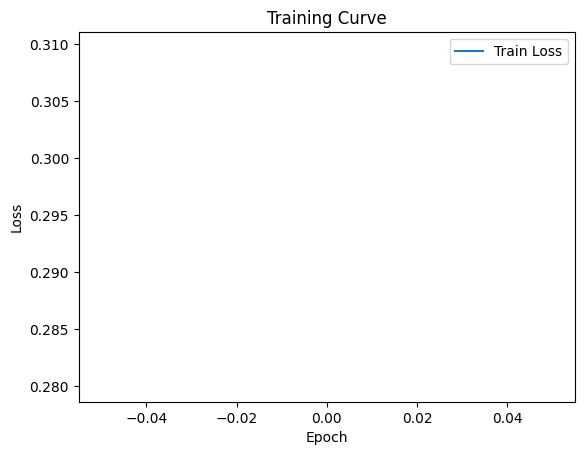

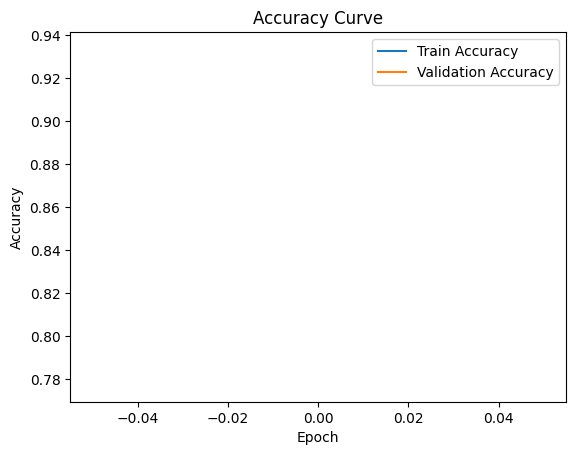



Testing Dropout Rate: 0.3
Epoch 1; Loss 0.364168; Train Acc 0.900247; Val Acc 0.731493
Total time elapsed: 122.90 seconds


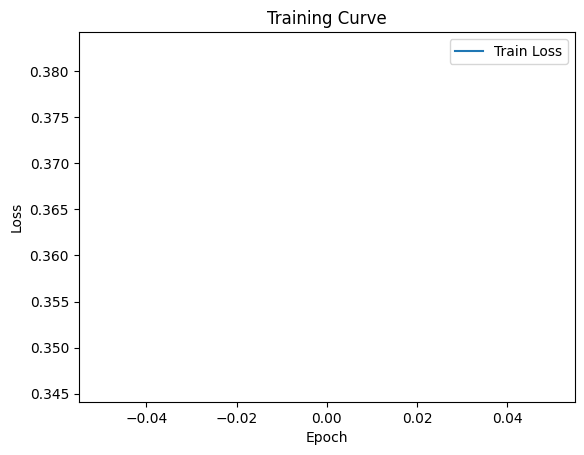

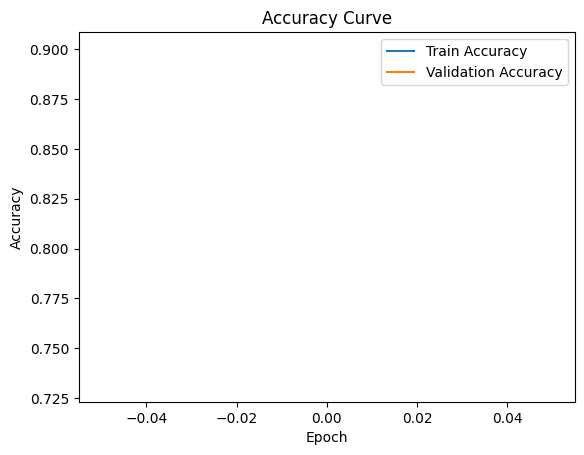



Testing Dropout Rate: 0.4
Epoch 1; Loss 0.399477; Train Acc 0.914254; Val Acc 0.777006
Total time elapsed: 122.91 seconds


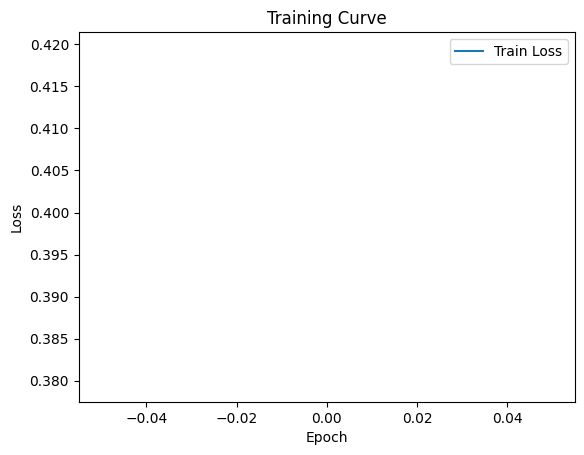

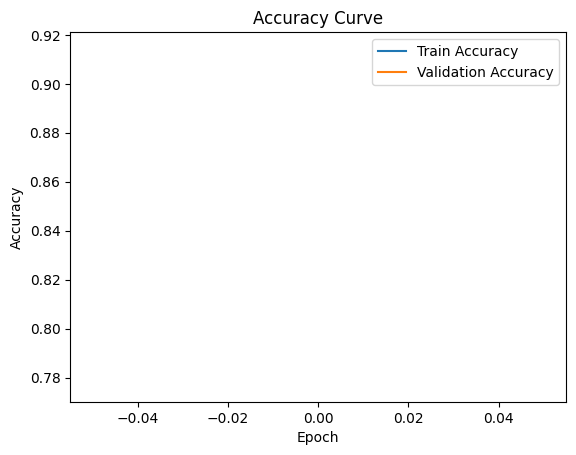



Testing Dropout Rate: 0.5
Epoch 1; Loss 0.335858; Train Acc 0.935751; Val Acc 0.829647
Total time elapsed: 122.08 seconds


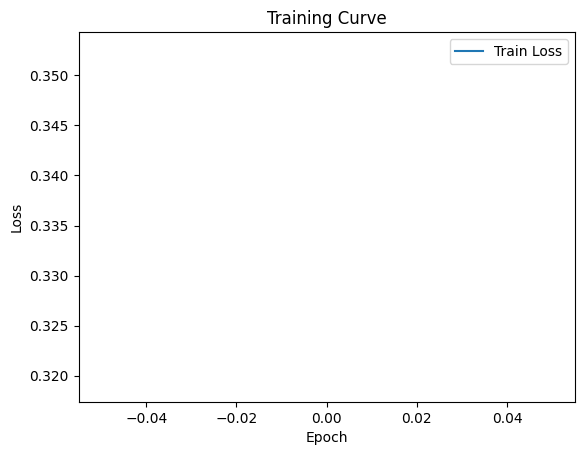

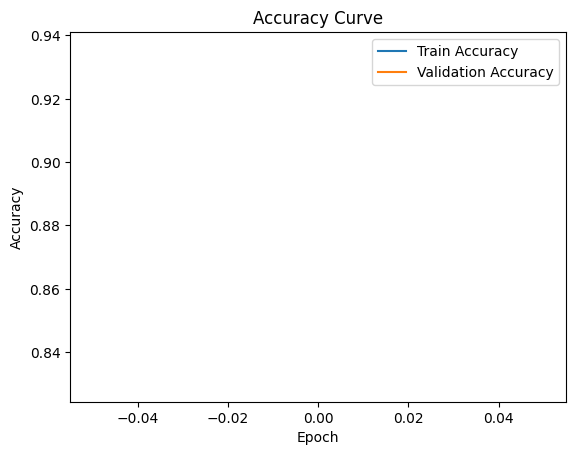

In [35]:
def test_dropout_rate(train_loader, val_loader, dropout_rates, input_size, hidden_size, num_classes, num_layers, num_epochs, learning_rate):
    for dropout_rate in dropout_rates:
        print(f"Testing Dropout Rate: {dropout_rate}")
        model = RNN(input_size, hidden_size, num_classes, num_layers, bidirectional)
        model.dropout_rate = dropout_rate
        train_rnn_network("LSTM_dr_" + str(dropout_rate), model, train_loader, val_loader, num_epochs, learning_rate)
        print("\n")

dropout_rates = [0.2, 0.3, 0.4, 0.5]
test_dropout_rate(train_loader, val_loader, dropout_rates, input_size, hidden_size, num_classes, num_layers, num_epochs, learning_rate)


### Combination of Hyperparameter Choices

Validating the accuracy of hyperparameter combination choices.

Epoch 1; Loss 0.163897; Train Acc 0.968515; Val Acc 0.869768
Epoch 2; Loss 0.050401; Train Acc 0.976493; Val Acc 0.826083
Total time elapsed: 243.26 seconds


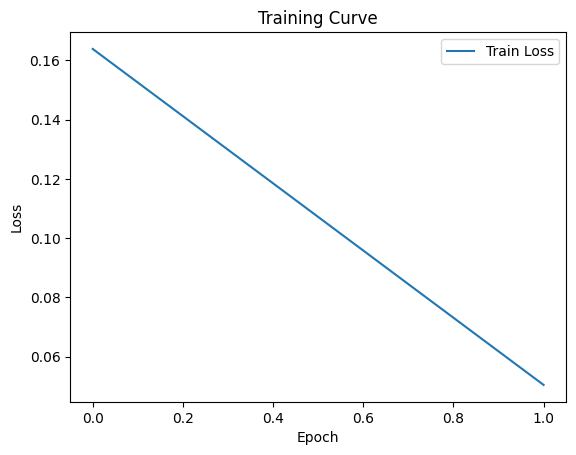

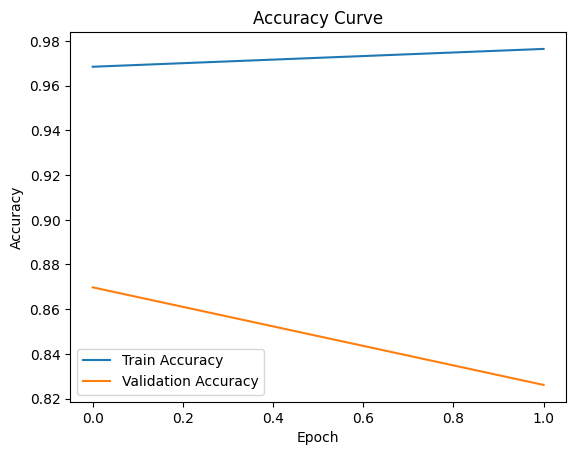

In [36]:
# Combination 1

learning_rate = 0.001
hidden_size = 100
num_layers = 1
dropout_rate = 0.2
input_size = input_size
num_classes = num_classes
lstm_model = RNN(input_size,hidden_size,num_classes,num_layers, bidirectional)
best_model1 = train_rnn_network("LSTM", lstm_model, train_loader, val_loader, num_epochs=2, learning_rate=learning_rate)


Epoch 1; Loss 0.242832; Train Acc 0.912274; Val Acc 0.842533
Epoch 2; Loss 0.111334; Train Acc 0.953168; Val Acc 0.836319
Total time elapsed: 220.98 seconds


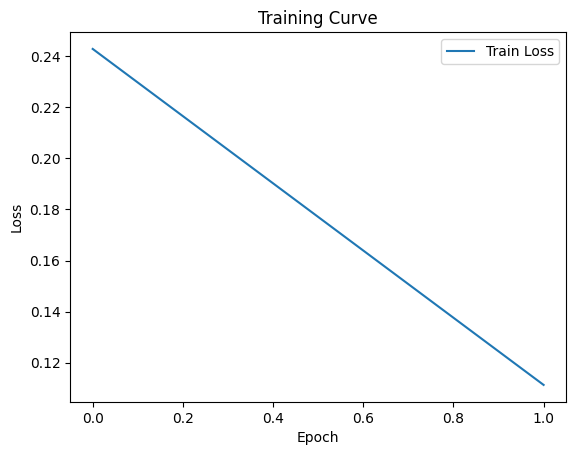

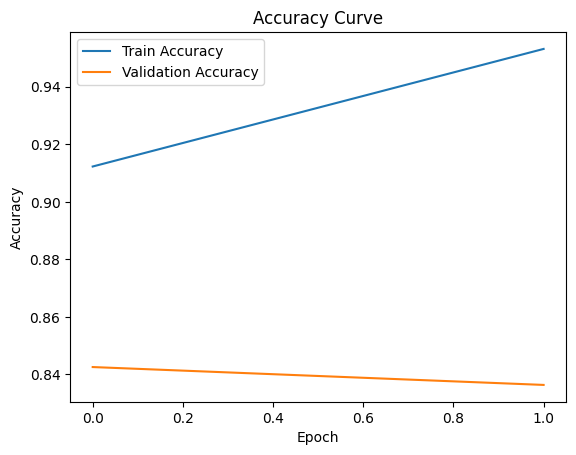

In [37]:
# Combination 2

learning_rate = 0.001
hidden_size = 50
num_layers = 2
dropout_rate = 0.2
input_size = input_size
num_classes = num_classes
lstm_model = RNN(input_size,hidden_size,num_classes,num_layers, bidirectional)
best_model2 = train_rnn_network("LSTM", lstm_model, train_loader, val_loader, num_epochs=2, learning_rate=learning_rate)

Epoch 1; Loss 0.206961; Train Acc 0.959319; Val Acc 0.853500
Epoch 2; Loss 0.065770; Train Acc 0.975853; Val Acc 0.867209
Total time elapsed: 116.56 seconds


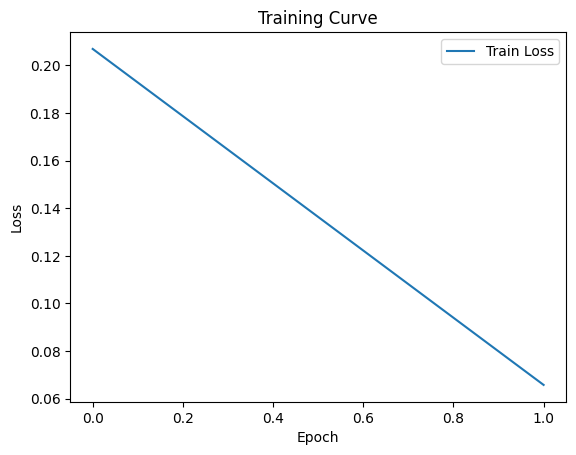

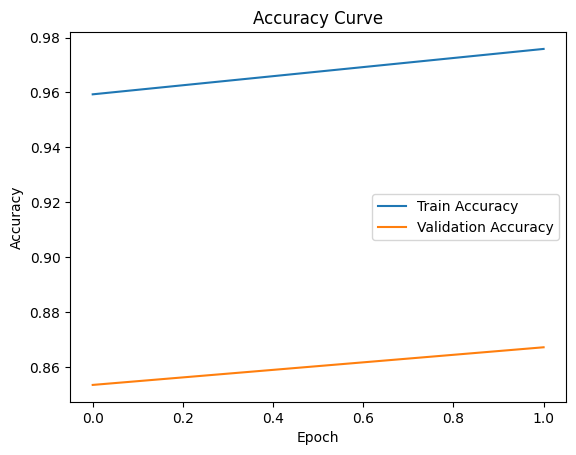

In [38]:
#Combination 3

learning_rate = 0.001
hidden_size = 50
num_layers = 1
dropout_rate = 0.3
input_size = input_size
num_classes = num_classes
lstm_model = RNN(input_size,hidden_size,num_classes,num_layers, bidirectional)
best_model3=train_rnn_network("LSTM",lstm_model, train_loader, val_loader, num_epochs=2, learning_rate=learning_rate)

Epoch 1; Loss 0.238352; Train Acc 0.936999; Val Acc 0.920124
Epoch 2; Loss 0.073807; Train Acc 0.962334; Val Acc 0.804606
Total time elapsed: 446.36 seconds


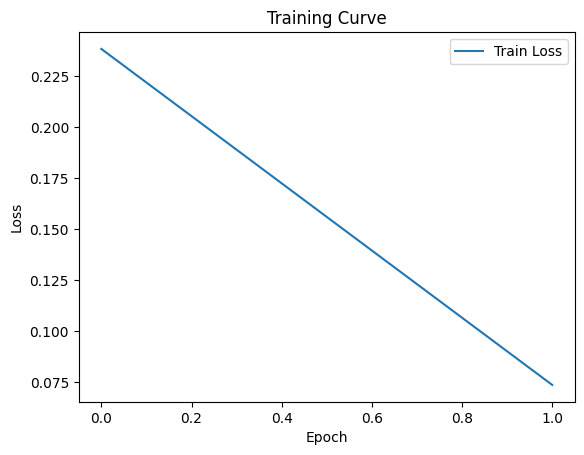

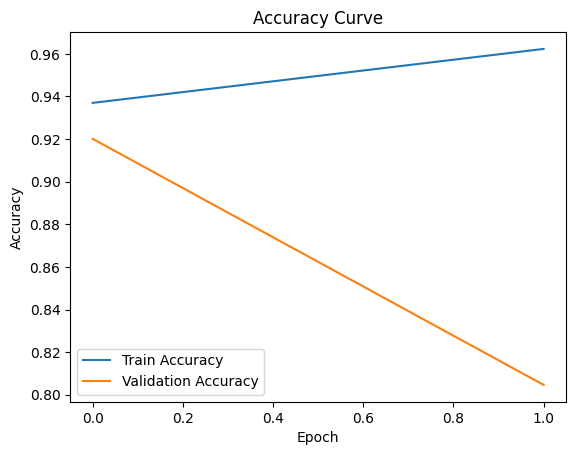

In [41]:
# Combination 4

learning_rate = 0.001
hidden_size = 100
num_layers = 2
dropout_rate = 0.3
num_epochs = 2
input_size = input_size
num_classes = num_classes
lstm_model = RNN(input_size,hidden_size,num_classes,num_layers, bidirectional)
best_model4=train_rnn_network("LSTM",lstm_model, train_loader, val_loader, num_epochs=2, learning_rate=learning_rate)

Epoch 1; Loss 0.278320; Train Acc 0.931579; Val Acc 0.837324
Epoch 2; Loss 0.094226; Train Acc 0.961938; Val Acc 0.807805
Total time elapsed: 116.65 seconds


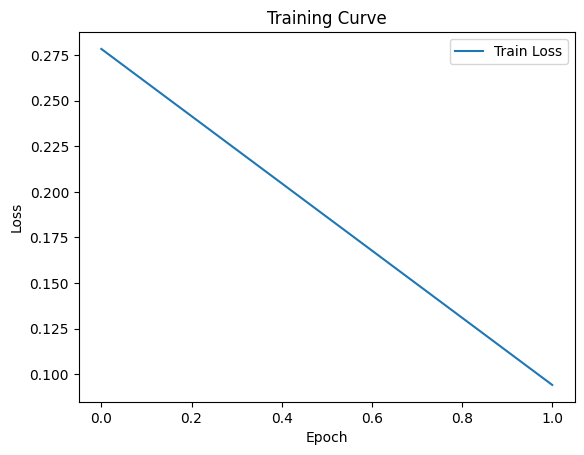

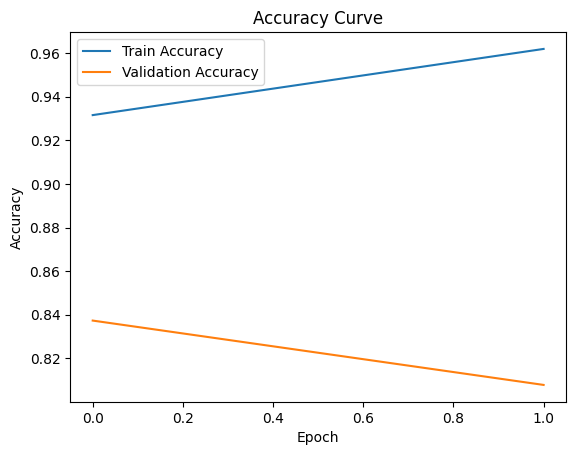

In [39]:
# Combination 5

learning_rate = 0.0005
hidden_size = 50
num_layers = 1
dropout_rate = 0.2
num_epochs = 2
input_size = input_size
num_classes = num_classes
lstm_model = RNN(input_size,hidden_size,num_classes,num_layers, bidirectional)
best_model5=train_rnn_network("LSTM",lstm_model, train_loader, val_loader, num_epochs=2, learning_rate=learning_rate)

Epoch 1; Loss 0.213727; Train Acc 0.949636; Val Acc 0.837598
Epoch 2; Loss 0.073128; Train Acc 0.971499; Val Acc 0.891245
Total time elapsed: 116.98 seconds


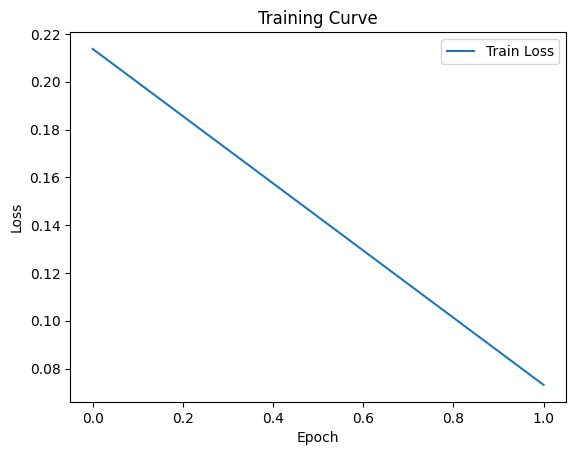

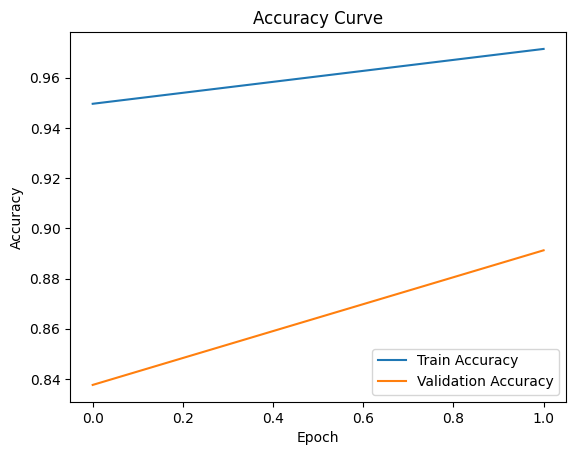

In [40]:
# Combination 6

learning_rate = 0.001
hidden_size = 50
num_layers = 1
dropout_rate = 0.2
num_epochs = 2
input_size = input_size
num_classes = num_classes
lstm_model = RNN(input_size,hidden_size,num_classes,num_layers, bidirectional)
best_model6=train_rnn_network("LSTM",lstm_model, train_loader, val_loader, num_epochs=2, learning_rate=learning_rate)


## Final Model Testing
Running the testing data through the best model as seen through the validation process. Since Combination 6 showed the best results, this is the model that will be tested.

In [29]:
test_loader = torch.utils.data.DataLoader(test_list, batch_size=1, shuffle=True)

Since combination 1 had the highest validation accuracy, the same hyperparameters will be used in the final model.

Epoch 1; Loss 0.184036; Train Acc 0.961633; Val Acc 0.828094
Total time elapsed: 116.13 seconds


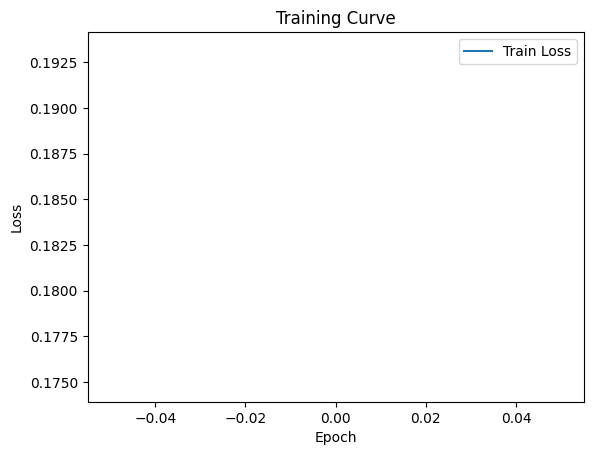

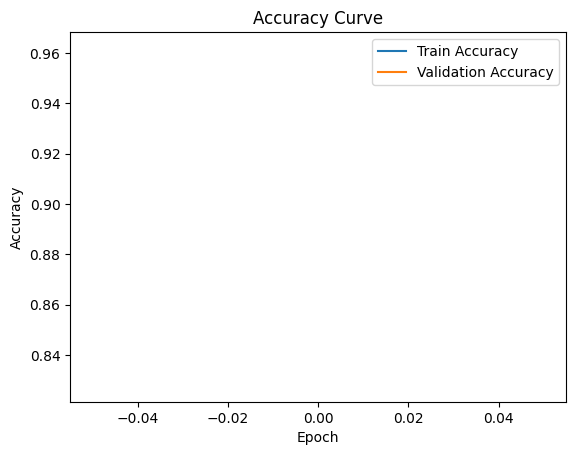

RNN(
  (emb): Embedding(400001, 50)
  (rnn): LSTM(50, 100, batch_first=True)
  (norm): LayerNorm((100,), eps=1e-05, elementwise_affine=True)
  (fc): Linear(in_features=100, out_features=2, bias=True)
)

In [41]:
final_model = RNN(input_size=50,hidden_size=100,num_class=2,num_layers=1, bidirectional=False)
final_model.dropout_rate = 0.2
train_rnn_network("FinalLSTM",final_model, train_loader, val_loader, num_epochs=1, learning_rate=0.001)

In [42]:
def evaluate_model_on_test_data(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for text, labels in test_loader:
            outputs = model(text)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predicted.cpu().numpy())

    accuracy = correct / total
    # print('Test Accuracy: {:.2f}%'.format(accuracy))

    return accuracy

In [43]:
test_acc=(evaluate_model_on_test_data(final_model, test_loader))
print("Test Accuracy: {:.4f}".format(test_acc))

Test Accuracy: 0.8363


# Demo

Demonstration of the model in a mode with UI elements.

In [44]:
pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [45]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import torch
import torch.nn as nn
from torchtext.vocab import GloVe

In [48]:
default_model = RNN(input_size=50, hidden_size=100, num_class=2, num_layers=1, bidirectional=False)
default_model.load_state_dict(torch.load("model_FinalLSTM_epoch1.pth"))
default_model.eval()

RNN(
  (emb): Embedding(400001, 50)
  (rnn): LSTM(50, 100, batch_first=True)
  (norm): LayerNorm((100,), eps=1e-05, elementwise_affine=True)
  (fc): Linear(in_features=100, out_features=2, bias=True)
)

In [50]:
final_model = RNN(input_size=50, hidden_size=100, num_class=2, num_layers=1, bidirectional=False)
final_model.load_state_dict(torch.load("model_FinalLSTM_epoch1.pth"))
final_model.eval()

RNN(
  (emb): Embedding(400001, 50)
  (rnn): LSTM(50, 100, batch_first=True)
  (norm): LayerNorm((100,), eps=1e-05, elementwise_affine=True)
  (fc): Linear(in_features=100, out_features=2, bias=True)
)

In [51]:
def remove_nonwanted_characters(string_input):

  characters_allowed = "abcdefghijklmnopqrstuvwxyz' "

  #if we want to remove the '
  #characters_allowed = "abcdefghijklmnopqrstuvwxyz "

  return ''.join(character for character in string_input if character in characters_allowed)

In [52]:
def clean_input(input):
  input = input.lower()
  input = remove_nonwanted_characters(input)
  return input

In [54]:
model_selector = widgets.Dropdown(
    options={'Default Model': default_model, 'Final Model': final_model},
    value=final_model,
    description='Model:',
    disabled=False,
)

text_input = widgets.Textarea(
    placeholder='Type the text...',
    description='Input:',
    disabled=False,
    layout=widgets.Layout(width='500px', height='200px')
)


analyze_button = widgets.Button(
    description='Analyze',
    disabled=False,
    button_style='success',  # 'success', 'info', 'warning', 'danger'
    tooltip='Click to analyze the text',
    icon='check'
)


output = widgets.Output()


def analyze_text(b):
    with output:
        clear_output()
        input_text = text_input.value
        input_text = clean_input(input_text)
        selected_model = model_selector.value
        idxs = [glove.stoi[w] for w in input_text.split() if w in glove.stoi]
        if not idxs:
            print("No valid text.")
            return
        idxs = torch.tensor(idxs).unsqueeze(0)
        with torch.no_grad():
            prediction = selected_model(idxs)
            predicted_class = torch.argmax(prediction, dim=1).item()
            confidence = torch.softmax(prediction, dim=1).max().item() * 100

            if predicted_class == 1:
                print(f"AI generated text. (Accuracy: {confidence:.2f}%)")
            else:
                print(f"Human Wrote this text. (Accuracy: {confidence:.2f}%)")


analyze_button.on_click(analyze_text)


display(model_selector, text_input, analyze_button, output)


Dropdown(description='Model:', index=1, options={'Default Model': RNN(
  (emb): Embedding(400001, 50)
  (rnn):…

Textarea(value='', description='Input:', layout=Layout(height='200px', width='500px'), placeholder='Type the t…

Button(button_style='success', description='Analyze', icon='check', style=ButtonStyle(), tooltip='Click to ana…

Output()

In [55]:
from IPython.display import FileLink
FileLink('model_FinalLSTM_epoch1.pth')

/kaggle/working/model_FinalLSTM_epoch1.pth